# Tanka Raj Aryal



## Task 1: SVM Classification
 Support Vector Machine (SVM) classification to the Breast Cancer Wisconsin Diagnostic
dataset.

### Dataset Selection

We selected Breast Cancer Wisconsin Diagnostic dataset because it was also used in Assignment 1. This allows us to compare the results of SVM with the kNN algorithm.

The dataset contains 569 samples and 30 numerical features. The dataset is suitable for supervised binary classification.



In [9]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

cancer = load_breast_cancer()

print("Samples:", cancer.data.shape[0])
print("Features:", cancer.feature_names)
print("Classes:", cancer.target_names)



Samples: 569
Features: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Classes: ['malignant' 'benign']


In [6]:
# Select all 30 features
X = cancer.data
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = SVC(kernel="linear", C=1)
model.fit(X_train, y_train)

# Predict on the TEST set
y_pred = model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

Test accuracy: 97.37%
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



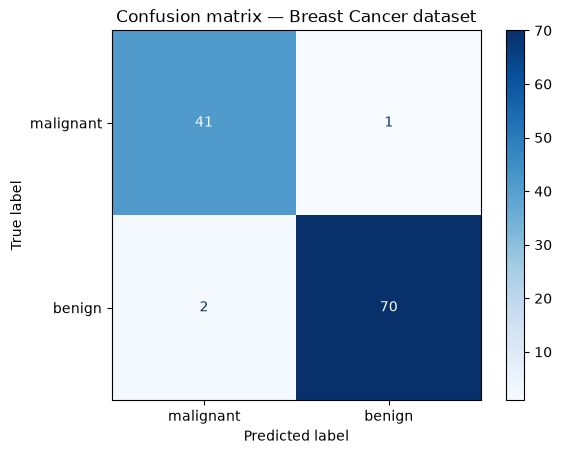

In [7]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=cancer.target_names, cmap="Blues"
)
plt.title("Confusion matrix — Breast Cancer dataset")
plt.show()

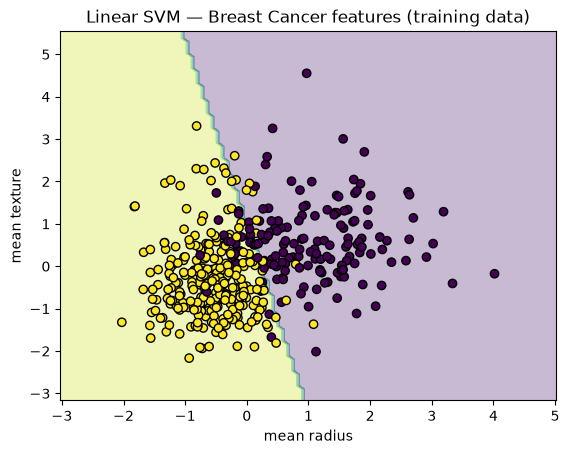

In [8]:
# Select two features: mean radius and mean texture
X_2d = cancer.data[:, :2]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y, test_size=0.20, random_state=42, stratify=y
)

scaler_2d = StandardScaler()
X_train_2d = scaler_2d.fit_transform(X_train_2d)
X_test_2d = scaler_2d.transform(X_test_2d)

model_2d = SVC(kernel="linear", C=1)
model_2d.fit(X_train_2d, y_train_2d)

# Same built-in visualization
DecisionBoundaryDisplay.from_estimator(
    model_2d, X_train_2d, response_method="predict", alpha=0.3
)
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1],
            c=y_train_2d, edgecolors="black")
plt.xlabel(cancer.feature_names[0])
plt.ylabel(cancer.feature_names[1])
plt.title("Linear SVM — Breast Cancer features (training data)")
plt.show()

In [10]:
# Train a polynomial SVM

poly_model = SVC(kernel="poly", degree=3, C=1)
poly_model.fit(X_train, y_train)

# Predict on the TEST set
poly_pred = poly_model.predict(X_test)

print(f"Polynomial SVM test accuracy: {accuracy_score(y_test, poly_pred):.2%}")

Polynomial SVM test accuracy: 91.23%


### Kernel Selection

We used two SVM kernels in this assignment:

- **Linear kernel:** Creates a linear decision boundary to separate the two classes.
- **Polynomial kernel:** Uses a polynomial function to model more complex relationships between the features.

And we tested both kernels using the same training and testing datasets.

## Task 2: Real-World Applications of SVM

### 1. Text Classification

SVM is used in spam email detection and news categorization. Text data can contain thousands of features, such as word frequencies and TF-IDF values. SVM can classify this high-dimensional data into different categories by finding a decision boundary between them.

### 2. Image Recognition

SVM is used in image classification to identify and categorize images. Images can be represented using thousands of numerical features, such as pixel values or extracted image features. SVM can use these high-dimensional features to distinguish between different image categories.